# 12. Phân tầng theo độ trễ quan sát

Câu hỏi nghiên cứu thứ hai của đề tài giả định rằng lợi ích của neo quan sát thật phụ thuộc vào khoảng thời gian kể từ phép đo thật gần nhất. Tuần 2 chỉ báo cáo một con số chung cho mọi khoảng trễ, nên chưa trả lời được câu hỏi đó.

Định nghĩa khoảng trễ dùng trong sổ tay này: với một điểm mục tiêu ở bước thứ `h` của kênh `c`, khoảng trễ bằng số giờ từ phép đo thật gần nhất của kênh `c` trong cửa sổ đầu vào đến điểm đó. Kênh không có phép đo nào trong cửa sổ được xếp vào một tầng riêng, vì khi đó hai neo trùng nhau về định nghĩa và hiệu ứng phải bằng không.

Thiết kế: dùng lại trọng số đã lưu của notebook 11 nếu có, huấn luyện bù nếu không tìm thấy. Sai số được tách theo sáu tầng khoảng trễ, mỗi tầng kèm khoảng tin cậy lấy mẫu lặp ở cấp bệnh nhân. Chi phí ước lượng khoảng mười lăm phút nếu phải huấn luyện lại, khoảng ba phút nếu đã có trọng số.

> **Vị trí trong chuỗi tái lập:** notebook 12 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 11-Chi_so_theo_nhom_kenh.
>
> **Thư mục kết quả:** `Output/processed/w3_19_phan_tang_theo_do_tre/`.
>
> **Mã định danh nội bộ:** `W3_19`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_19_phan_tang_theo_do_tre"  #@param {type:"string"}
DANH_SACH_NEO = "A,B"  #@param {type:"string"}
NGUON_TRONG_SO = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
BIEN_TANG = "2,4,8,16,36"  #@param {type:"string"}
N_BOOT = 2000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

NEO = [t.strip() for t in DANH_SACH_NEO.split(",") if t.strip()]
BIEN = [int(t) for t in BIEN_TANG.split(",") if t.strip()]
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_19_phan_tang_theo_do_tre
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:29:57
run_tag      w3_19_phan_tang_theo_do_tre
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Một hàm dự báo duy nhất cho mọi phép phân tích chi tiết, để không có hai nhánh mã
# Khác nhau cùng tính một đại lượng.
def du_bao_tap_kiem_tra(model):
    model.eval()
    phan = []
    with torch.no_grad():
        for x, mxx, y, myy in DataLoader(SPLITS["test"], batch_size=BATCH, shuffle=False):
            phan.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    return np.concatenate(phan).astype(np.float64)


Y_TEST = SPLITS["test"].tensors[2].numpy().astype(np.float64)
M_TEST = SPLITS["test"].tensors[3].numpy().astype(np.float64)
X_TEST = SPLITS["test"].tensors[0].numpy().astype(np.float64)
MX_TEST = SPLITS["test"].tensors[1].numpy().astype(np.float64)
print("Tập kiểm tra:", Y_TEST.shape[0], "hồ sơ |", int(M_TEST.sum()), "điểm quan sát thật")


Tập kiểm tra: 1585 hồ sơ | 136752 điểm quan sát thật


## 3. Lấy mô hình, ưu tiên dùng lại trọng số đã lưu

Hàm dưới đây tìm tệp trọng số trong thư mục của notebook 11. Khi nạp lại trọng số, sổ tay kiểm tra ngay sai số bình phương chung và đối chiếu với con số đã ghi trong tệp kết quả của notebook 11. Sai lệch vượt một phần nghìn sẽ làm dừng sổ tay, vì điều đó có nghĩa là dữ liệu hoặc cấu hình đã thay đổi giữa hai sổ tay.

In [10]:
SEEDS = list(range(N_SEEDS))
THU_MUC_TRONG_SO = OUT / "processed" / NGUON_TRONG_SO / "runs"
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

NGUON_GOC = {}


def lay_mo_hinh(neo, seed):
    ten = "nlinear_neo" + neo + "_mse_s" + str(seed)
    tep = THU_MUC_TRONG_SO / (ten + ".pt")
    if tep.exists():
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind="nlinear", anchor=neo).to(DEVICE)
        model.load_state_dict(torch.load(tep, map_location=DEVICE))
        MO_HINH_DA_HUAN_LUYEN[ten] = model
        NGUON_GOC[ten] = NGUON_TRONG_SO
        print("Nạp lại trọng số", ten)
    else:
        print("Không thấy trọng số", ten, "nên huấn luyện mới")
        chay_mot_cau_hinh("nlinear", anchor=neo, seed=seed, nhan=ten)
        NGUON_GOC[ten] = RUN_TAG
    return ten


TEN_MO_HINH = {neo: [lay_mo_hinh(neo, s) for s in SEEDS] for neo in NEO}
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
Nạp lại trọng số nlinear_neoA_mse_s0
Nạp lại trọng số nlinear_neoA_mse_s1
Nạp lại trọng số nlinear_neoA_mse_s2
Nạp lại trọng số nlinear_neoB_mse_s0
Nạp lại trọng số nlinear_neoB_mse_s1
Nạp lại trọng số nlinear_neoB_mse_s2
Tổng thời gian: 0.1 phút


In [11]:
# Đối chiếu sai số bình phương chung với tệp kết quả của notebook 11.
def mse_chung(ten):
    yhat = du_bao_tap_kiem_tra(MO_HINH_DA_HUAN_LUYEN[ten])
    return float((M_TEST * (yhat - Y_TEST) ** 2).sum() / (M_TEST.sum() + EPS))


MSE_TINH_LAI = {neo: float(np.mean([mse_chung(t) for t in TEN_MO_HINH[neo]]))
                for neo in NEO}
for neo, v in MSE_TINH_LAI.items():
    print("Neo", neo, "| sai số bình phương chung", round(v, 6))

tep_18 = OUT / "processed" / NGUON_TRONG_SO / "W3_chi_so_theo_nhom_kenh.json"
if tep_18.exists():
    d18 = json.loads(tep_18.read_text())
    tong_diem = sum(r["so_diem_muc_tieu"] for r in d18["bang_kenh"])
    for neo in NEO:
        khoa = "mse_neo" + neo
        tu = sum((r[khoa] or 0.0) * r["so_diem_muc_tieu"] for r in d18["bang_kenh"])
        cho_doi = tu / max(tong_diem, 1.0)
        lech = abs(cho_doi - MSE_TINH_LAI[neo])
        print("Neo", neo, "| ghi nhận của notebook 11", round(cho_doi, 6),
              "| sai lệch", round(lech, 8))
        assert lech < 1e-3, "Sai lệch quá lớn so với notebook 11"
else:
    print("Không thấy tệp kết quả của notebook 11, bỏ qua bước đối chiếu")


Neo A | sai số bình phương chung 0.488031
Neo B | sai số bình phương chung 0.436036
Neo A | ghi nhận của notebook 11 0.488031 | sai lệch 0.0
Neo B | ghi nhận của notebook 11 0.436036 | sai lệch 0.0


## 4. Tính khoảng trễ của từng điểm mục tiêu

Khoảng trễ được tính một lần duy nhất cho cả hai neo, vì nó là thuộc tính của dữ liệu chứ không phải của mô hình. Nhờ vậy hai neo được so trên cùng một cách phân tầng.

In [12]:
xt = torch.from_numpy(X_TEST).float()
mt = torch.from_numpy(MX_TEST).float()
_, dt_kenh = last_observed(xt, mt)
dt_kenh = dt_kenh.numpy()
co_quan_sat = MX_TEST.sum(axis=1) > 0

buoc = np.arange(1, PRED_LEN + 1).reshape(1, PRED_LEN, 1)
DO_TRE = dt_kenh[:, None, :] + buoc

TEN_TANG = []
ma_tang = np.full(DO_TRE.shape, -1, dtype=np.int64)
truoc = 0
for i, b in enumerate(BIEN):
    chon = (DO_TRE > truoc) & (DO_TRE <= b)
    ma_tang = np.where(chon, i, ma_tang)
    TEN_TANG.append(str(truoc + 1) + " đến " + str(b) + " giờ")
    truoc = b
chon = DO_TRE > truoc
ma_tang = np.where(chon, len(BIEN), ma_tang)
TEN_TANG.append("trên " + str(truoc) + " giờ")

# Tầng riêng cho kênh không có phép đo thật nào trong cửa sổ đầu vào.
khong_quan_sat = np.repeat(~co_quan_sat[:, None, :], PRED_LEN, axis=1)
ma_tang = np.where(khong_quan_sat, len(TEN_TANG), ma_tang)
TEN_TANG.append("không có phép đo trong cửa sổ")

for i, ten in enumerate(TEN_TANG):
    so_diem = float((M_TEST * (ma_tang == i)).sum())
    print(ten.ljust(30), int(so_diem), "điểm |",
          round(100.0 * so_diem / (M_TEST.sum() + EPS), 2), "phần trăm")


1 đến 2 giờ                    17851 điểm | 13.05 phần trăm
3 đến 4 giờ                    21043 điểm | 15.39 phần trăm
5 đến 8 giờ                    40933 điểm | 29.93 phần trăm
9 đến 16 giờ                   45922 điểm | 33.58 phần trăm
17 đến 36 giờ                  8193 điểm | 5.99 phần trăm
trên 36 giờ                    899 điểm | 0.66 phần trăm
không có phép đo trong cửa sổ  1911 điểm | 1.4 phần trăm


## 5. Sai số theo từng tầng và kiểm định bắt cặp

Với mỗi tầng, tổng sai số được lấy theo từng hồ sơ rồi trung bình qua các hạt giống, sau đó mới bắt cặp hai neo. Hồ sơ không có điểm nào thuộc tầng đang xét vẫn nằm trong phép lấy mẫu lặp với tổng bằng không, đúng như cách lấy mẫu cấp bệnh nhân đòi hỏi.

In [13]:
def tong_theo_ho_so_tang(ten_mo_hinh, ma):
    yhat = du_bao_tap_kiem_tra(MO_HINH_DA_HUAN_LUYEN[ten_mo_hinh])
    hieu = yhat - Y_TEST
    m = M_TEST * (ma_tang == ma)
    se = (m * hieu ** 2).sum(axis=(1, 2))
    ae = (m * np.abs(hieu)).sum(axis=(1, 2))
    return se, ae, m.sum(axis=(1, 2))


PHAN_TANG = {}
for i, ten in enumerate(TEN_TANG):
    goi = {}
    for neo in NEO:
        ses, aes, dem = [], [], None
        for t in TEN_MO_HINH[neo]:
            se, ae, d = tong_theo_ho_so_tang(t, i)
            ses.append(se)
            aes.append(ae)
            dem = d
        goi[neo] = (np.mean(ses, axis=0), np.mean(aes, axis=0), dem)
    so_diem = float(goi["A"][2].sum())
    if so_diem < 1.0:
        print("Tầng", ten, "không có điểm nào, bỏ qua")
        continue
    kq = hieu_so_bat_cap(goi["B"][0], goi["B"][1], goi["A"][0], goi["A"][1],
                         goi["A"][2], n_boot=N_BOOT, seed=0)
    PHAN_TANG[ten] = {
        "so_diem": so_diem,
        "ty_le_diem": so_diem / (M_TEST.sum() + EPS),
        "mse_neoA": float(goi["A"][0].sum() / (so_diem + EPS)),
        "mse_neoB": float(goi["B"][0].sum() / (so_diem + EPS)),
        "mae_neoA": float(goi["A"][1].sum() / (so_diem + EPS)),
        "mae_neoB": float(goi["B"][1].sum() / (so_diem + EPS)),
        "hieu_mse": kq["hieu_mse"], "hieu_mse_ci": kq["hieu_mse_ci"],
        "p_mse": kq["p_hai_phia_mse"],
        "hieu_mae": kq["hieu_mae"], "hieu_mae_ci": kq["hieu_mae_ci"],
        "p_mae": kq["p_hai_phia_mae"],
    }
    print(ten.ljust(30), "hiệu MSE", round(kq["hieu_mse"], 6),
          kq["hieu_mse_ci"], "p", round(kq["p_hai_phia_mse"], 4))


1 đến 2 giờ                    hiệu MSE -0.014152 [-0.01878634456641956, -0.00934708549031161] p 0.0
3 đến 4 giờ                    hiệu MSE -0.031623 [-0.039669054108540484, -0.023495864147118208] p 0.0
5 đến 8 giờ                    hiệu MSE -0.029616 [-0.03797060068416221, -0.019849103757398647] p 0.0
9 đến 16 giờ                   hiệu MSE -0.061731 [-0.07049600864904933, -0.05309807351972579] p 0.0
17 đến 36 giờ                  hiệu MSE -0.244185 [-0.306516412896772, -0.194660883270056] p 0.0
trên 36 giờ                    hiệu MSE -0.163566 [-0.33991783674819137, 0.015029955465975966] p 0.079
không có phép đo trong cửa sổ  hiệu MSE 0.001236 [-0.00123594579301095, 0.00351354407700278] p 0.316


In [14]:
# Kiểm tra dấu kỳ vọng: tầng không có phép đo phải cho hiệu tiệm cận không,
# Vì khi đó hai neo trùng nhau về định nghĩa.
ten_rong = "không có phép đo trong cửa sổ"
if ten_rong in PHAN_TANG:
    h = PHAN_TANG[ten_rong]["hieu_mse"]
    print("Hiệu ở tầng không có phép đo:", round(h, 6))
    print("Hiệu này phải rất nhỏ; giá trị lớn là dấu hiệu sai định nghĩa neo")

co_quan_sat_tang = [t for t in PHAN_TANG if t != ten_rong]
if len(co_quan_sat_tang) >= 2:
    tre = np.arange(len(co_quan_sat_tang), dtype=np.float64)
    hieu = np.array([PHAN_TANG[t]["hieu_mse"] for t in co_quan_sat_tang])
    tq = float(np.corrcoef(tre, hieu)[0, 1])
    print("Tương quan giữa thứ tự tầng trễ và hiệu ứng neo:", round(tq, 5))
else:
    tq = None
    print("Không đủ tầng để tính tương quan")


Hiệu ở tầng không có phép đo: 0.001236
Hiệu này phải rất nhỏ; giá trị lớn là dấu hiệu sai định nghĩa neo
Tương quan giữa thứ tự tầng trễ và hiệu ứng neo: -0.8187


## 6. Hình phân tầng

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_19_phan_tang_theo_do_tre/figures/W3_19_phan_tang_theo_do_tre.png


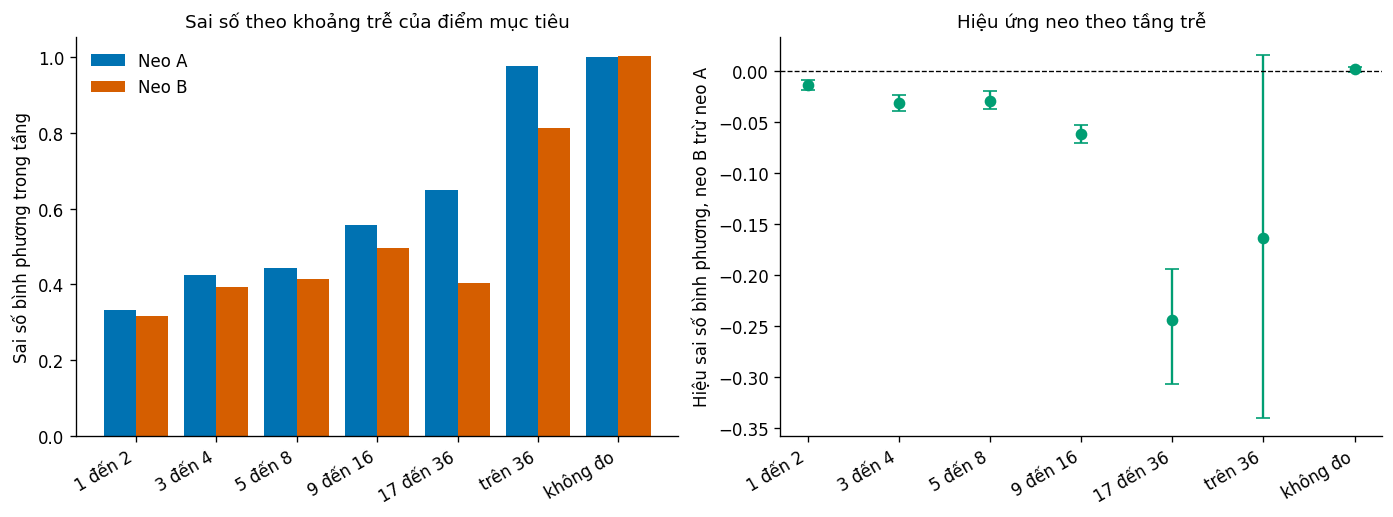

In [15]:
ten = list(PHAN_TANG)
nhan_ngan = [t.replace(" giờ", "").replace("không có phép đo trong cửa sổ", "không đo")
             for t in ten]
mse_a = [PHAN_TANG[t]["mse_neoA"] for t in ten]
mse_b = [PHAN_TANG[t]["mse_neoB"] for t in ten]
hieu = [PHAN_TANG[t]["hieu_mse"] for t in ten]
ci = [PHAN_TANG[t]["hieu_mse_ci"] for t in ten]
duoi = [g - x[0] for g, x in zip(hieu, ci)]
tren = [x[1] - g for g, x in zip(hieu, ci)]
vi_tri = np.arange(len(ten))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax[0].bar(vi_tri - 0.2, mse_a, width=0.4, label="Neo A", color=PALETTE[0])
ax[0].bar(vi_tri + 0.2, mse_b, width=0.4, label="Neo B", color=PALETTE[1])
ax[0].set_xticks(vi_tri)
ax[0].set_xticklabels(nhan_ngan, rotation=30, ha="right")
ax[0].set_ylabel("Sai số bình phương trong tầng")
ax[0].set_title("Sai số theo khoảng trễ của điểm mục tiêu")
ax[0].legend()
ax[1].errorbar(vi_tri, hieu, yerr=[duoi, tren], fmt="o", color=PALETTE[2], capsize=4)
ax[1].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
ax[1].set_xticks(vi_tri)
ax[1].set_xticklabels(nhan_ngan, rotation=30, ha="right")
ax[1].set_ylabel("Hiệu sai số bình phương, neo B trừ neo A")
ax[1].set_title("Hiệu ứng neo theo tầng trễ")
luu_hinh(fig, "W3_19_phan_tang_theo_do_tre.png")
plt.show()


## 7. Ghi kết quả

In [16]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "n_boot": N_BOOT, "bien_tang": BIEN,
    "nguon_trong_so": NGUON_GOC,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "mse_chung_tinh_lai": MSE_TINH_LAI,
    "tuong_quan_tang_va_hieu_ung": tq,
    "phan_tang": PHAN_TANG,
}
dich = RUN_DIR / "W3_phan_tang_theo_do_tre.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_19_phan_tang_theo_do_tre/W3_phan_tang_theo_do_tre.json
